In [1]:
import sys
print(sys.executable)

c:\Users\saanv\TSAF_PROJ\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import statsmodels
import sklearn
import xgboost
import prophet
import holidays
import requests
import tensorflow as tf

print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)
print("statsmodels ", statsmodels.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost     ", xgboost.__version__)
print("prophet     ", prophet.__version__)
print("holidays    ", holidays.__version__)
print("tensorflow  ", tf.__version__)
print("\nAll imports OK")

Matplotlib is building the font cache; this may take a moment.
Importing plotly failed. Interactive plots will not work.


pandas       3.1.0
numpy        2.5.4
matplotlib   3.11.2
seaborn      0.13.2
statsmodels  0.15.0
scikit-learn 1.9.1
xgboost      3.4.1
prophet      1.5.0
holidays     0.108
tensorflow   2.21.0

All imports OK


In [3]:
df = pd.read_csv("../data/processed/bangalore_traffic_weather.csv",
                 parse_dates=["LocalDateTime"]).set_index("LocalDateTime")

print("Shape:", df.shape)
print("\nIndex type:", type(df.index).__name__)
print("\nColumns and data types:")
print(df.dtypes)
print("\nFirst 3 rows:")
display(df.head(3))
print("\nLast 3 rows:")
display(df.tail(3))

Shape: (15829, 20)

Index type: DatetimeIndex

Columns and data types:
Country                               str
City                                  str
UpdateTimeUTC                         str
JamsDelay                         float64
TrafficIndexLive                  float64
JamsLengthInKms                   float64
JamsCount                         float64
LocalDateTimeWeekAgo                  str
TrafficIndexWeekAgo               float64
TravelTimeLivePer10KmsMins        float64
TravelTimeHistoricPer10KmsMins    float64
MinsDelay                         float64
temperature_2m                    float64
relative_humidity_2m                int64
precipitation                     float64
rain                              float64
cloud_cover                         int64
wind_speed_10m                    float64
is_raining                          int64
rain_3h                           float64
dtype: object

First 3 rows:


,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,LocalDateTimeWeekAgo,TrafficIndexWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay,temperature_2m,relative_humidity_2m,precipitation,rain,cloud_cover,wind_speed_10m,is_raining,rain_3h
LocalDateTime,,,,,,,,,,,,,,,,,,,,
2025-01-07 11:00:00,IND,bengaluru,2025-01-07 06:15:00.000,357.7,59.0,38.1,104.0,2024-12-31 11:00:00,45.0,37.833333,34.666667,3.166667,24.6,48,0.0,0.0,0,5.7,0,0.0
2025-01-07 12:00:00,IND,bengaluru,2025-01-07 06:30:00.000,376.1,58.0,39.2,103.0,2024-12-31 12:00:00,45.0,37.666667,34.666667,3.000000,26.0,41,0.0,0.0,0,7.2,0,0.0
2025-01-07 13:00:00,IND,bengaluru,2025-01-07 07:30:00.000,362.5,56.0,37.5,100.0,2024-12-31 13:00:00,43.0,37.000000,34.166667,2.833333,26.9,36,0.0,0.0,27,7.7,0,0.0



Last 3 rows:


,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,LocalDateTimeWeekAgo,TrafficIndexWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay,temperature_2m,relative_humidity_2m,precipitation,rain,cloud_cover,wind_speed_10m,is_raining,rain_3h
LocalDateTime,,,,,,,,,,,,,,,,,,,,
2026-10-28 21:00:00,IND,bengaluru,2026-10-28 15:30:00.001,145.9,48.0,15.9,41.0,2026-10-21 21:00:00,41.0,36.333333,34.500000,1.833333,22.2,60,0.0,0.0,1,6.2,0,0.0
2026-10-28 22:00:00,IND,bengaluru,2026-10-28 16:30:00.000,44.4,29.0,6.7,16.0,2026-10-21 22:00:00,25.0,31.166667,30.166667,1.000000,21.4,63,0.0,0.0,2,8.5,0,0.0
2026-10-28 23:00:00,IND,bengaluru,2026-10-28 17:30:00.000,5.0,13.0,0.5,2.0,2026-10-21 23:00:00,6.0,27.166667,25.500000,1.666667,20.5,69,0.0,0.0,0,9.8,0,0.0


In [4]:
print("Start:", df.index.min())
print("End:  ", df.index.max())
print("Hours expected between start and end:", int((df.index.max() - df.index.min()) / pd.Timedelta(hours=1)) + 1)
print("Rows in data:", len(df))

print("\nTime step counts:")
print(df.index.to_series().diff().value_counts())

print("\nDuplicate timestamps:", df.index.duplicated().sum())
print("Index sorted ascending:", df.index.is_monotonic_increasing)

Start: 2025-01-07 11:00:00
End:   2026-10-28 23:00:00
Hours expected between start and end: 15829
Rows in data: 15829

Time step counts:
LocalDateTime
0 days 01:00:00    15828
Name: count, dtype: int64

Duplicate timestamps: 0
Index sorted ascending: True


In [5]:
missing = df.isna().sum()
print("Missing values per column:")
print(missing.to_string())
print("\nTotal missing:", missing.sum())

# Also check for placeholder values that hide missing data
num = df.select_dtypes("number")
print("\nColumns containing infinite values:", [c for c in num.columns if np.isinf(num[c]).any()])
print("Columns containing negative values:", [c for c in num.columns if (num[c] < 0).any()])

Missing values per column:
Country                           0
City                              0
UpdateTimeUTC                     0
JamsDelay                         0
TrafficIndexLive                  0
JamsLengthInKms                   0
JamsCount                         0
LocalDateTimeWeekAgo              0
TrafficIndexWeekAgo               0
TravelTimeLivePer10KmsMins        0
TravelTimeHistoricPer10KmsMins    0
MinsDelay                         0
temperature_2m                    0
relative_humidity_2m              0
precipitation                     0
rain                              0
cloud_cover                       0
wind_speed_10m                    0
is_raining                        0
rain_3h                           0

Total missing: 0

Columns containing infinite values: []
Columns containing negative values: ['MinsDelay']


In [6]:
num_cols = df.select_dtypes("number").columns
summary = df[num_cols].describe().T[["min", "25%", "50%", "mean", "75%", "max", "std"]].round(2)
display(summary)

,min,25%,50%,mean,75%,max,std
JamsDelay,0.00,14.40,129.20,194.13,312.6,3470.20,215.75
TrafficIndexLive,0.00,0.00,33.00,30.75,52.0,173.00,26.26
JamsLengthInKms,0.00,1.20,13.60,20.61,34.7,230.20,22.26
JamsCount,0.00,4.00,37.00,51.71,87.0,511.00,52.57
TrafficIndexWeekAgo,0.00,0.00,32.00,26.55,45.0,70.00,22.07
TravelTimeLivePer10KmsMins,15.83,21.67,32.00,30.31,37.0,69.50,8.25
TravelTimeHistoricPer10KmsMins,16.17,21.00,31.50,29.14,35.5,41.67,7.50
MinsDelay,-11.33,0.17,0.83,1.16,2.0,29.50,2.04
temperature_2m,13.20,20.90,23.30,23.96,26.8,36.90,4.14
relative_humidity_2m,10.00,50.00,70.00,66.74,88.0,100.00,23.12


Share of zeros: 0.283
Hours with index above 100: 41

Percentiles:
0.50    33.0
0.75    52.0
0.90    65.0
0.95    73.0
0.99    87.0

Top 10 highest values:
LocalDateTime
2026-04-29 19:00:00    173.0
2026-04-29 20:00:00    166.0
2026-04-29 21:00:00    140.0
2026-04-29 18:00:00    138.0
2025-05-17 19:00:00    125.0
2025-05-17 18:00:00    124.0
2025-08-13 19:00:00    120.0
2026-10-15 19:00:00    117.0
2025-08-13 20:00:00    112.0
2025-09-18 19:00:00    112.0

Share of zeros by hour of day:
LocalDateTime
0     0.70
1     0.99
2     1.00
3     1.00
4     1.00
5     1.00
6     0.99
7     0.13
8     0.00
9     0.00
10    0.00
11    0.00
12    0.00
13    0.00
14    0.00
15    0.00
16    0.00
17    0.00
18    0.00
19    0.00
20    0.00
21    0.00
22    0.00
23    0.00


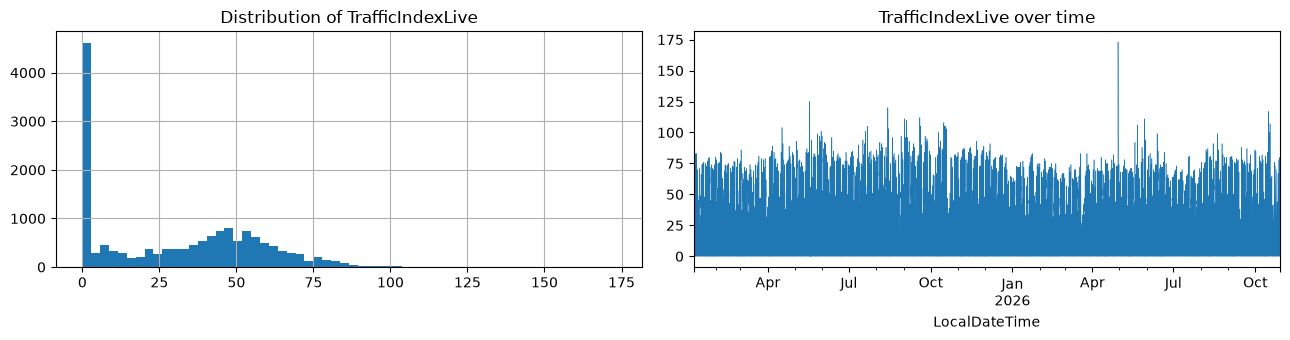

In [7]:
import matplotlib.pyplot as plt

y = df["TrafficIndexLive"]

print("Share of zeros:", round((y == 0).mean(), 3))
print("Hours with index above 100:", int((y > 100).sum()))

print("\nPercentiles:")
print(y.quantile([0.5, 0.75, 0.9, 0.95, 0.99]).round(1).to_string())

print("\nTop 10 highest values:")
print(y.nlargest(10).to_string())

print("\nShare of zeros by hour of day:")
print((y == 0).groupby(y.index.hour).mean().round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
y.hist(bins=60, ax=ax[0]); ax[0].set_title("Distribution of TrafficIndexLive")
y.plot(ax=ax[1], lw=0.4); ax[1].set_title("TrafficIndexLive over time")
plt.tight_layout(); plt.show()

In [8]:
weather_cols = ["temperature_2m", "relative_humidity_2m", "cloud_cover", "wind_speed_10m"]

monthly = pd.DataFrame({
    "rain_mm": df["precipitation"].resample("ME").sum(),
    "rainy_hours": df["is_raining"].resample("ME").sum(),
    "avg_temp": df["temperature_2m"].resample("ME").mean(),
    "avg_humidity": df["relative_humidity_2m"].resample("ME").mean(),
    "avg_cloud": df["cloud_cover"].resample("ME").mean(),
    "hours_in_data": df["temperature_2m"].resample("ME").count(),
}).round(1)

display(monthly)

print("Hottest hour:", df["temperature_2m"].idxmax(), df["temperature_2m"].max())
print("Heaviest rain hour:", df["precipitation"].idxmax(), df["precipitation"].max())

,rain_mm,rainy_hours,avg_temp,avg_humidity,avg_cloud,hours_in_data
LocalDateTime,,,,,,
2025-01-31,7.1,3,21.6,65.2,56.4,589
2025-02-28,0.0,0,24.4,43.5,36.6,672
2025-03-31,28.7,8,26.5,47.6,37.7,744
2025-04-30,31.6,12,27.1,54.6,39.9,720
2025-05-31,159.3,66,24.9,71.4,73.7,744
2025-06-30,85.6,34,23.5,77.4,90.7,720
2025-07-31,190.3,75,22.7,80.7,93.7,744
2025-08-31,175.7,79,22.3,83.8,94.9,744
2025-09-30,126.3,46,22.6,81.1,89.8,720


Hottest hour: 2026-04-27 14:00:00 36.9
Heaviest rain hour: 2026-05-18 16:00:00 16.9


In [9]:
y = df["TrafficIndexLive"]

# 1. Same-hour correlation of every numeric column with the target
num_cols = df.select_dtypes("number").columns.drop("TrafficIndexLive")
print("Correlation with TrafficIndexLive (same hour):")
print(df[num_cols].corrwith(y).round(3).sort_values(ascending=False).to_string())

# 2. Compare TomTom's TrafficIndexWeekAgo with our own 168-hour lag
own_lag168 = y.shift(168)
cmp = pd.DataFrame({"TomTom_WeekAgo": df["TrafficIndexWeekAgo"], "Own_lag168": own_lag168}).dropna()
print("\nTomTom WeekAgo vs own 168h lag:")
print(cmp.describe().round(1).to_string())
print("\nCorrelation between them:", round(cmp["TomTom_WeekAgo"].corr(cmp["Own_lag168"]), 3))
print("Mean absolute difference:", round((cmp["TomTom_WeekAgo"] - cmp["Own_lag168"]).abs().mean(), 2))

Correlation with TrafficIndexLive (same hour):
TravelTimeLivePer10KmsMins        0.980
TrafficIndexWeekAgo               0.952
JamsCount                         0.943
JamsLengthInKms                   0.935
TravelTimeHistoricPer10KmsMins    0.931
JamsDelay                         0.909
temperature_2m                    0.549
MinsDelay                         0.536
rain_3h                           0.171
wind_speed_10m                    0.133
precipitation                     0.118
rain                              0.118
is_raining                        0.106
cloud_cover                       0.021
relative_humidity_2m             -0.469

TomTom WeekAgo vs own 168h lag:
       TomTom_WeekAgo  Own_lag168
count         15661.0     15661.0
mean             26.6        30.8
std              22.1        26.3
min               0.0         0.0
25%               0.0         0.0
50%              32.0        33.0
75%              45.0        52.0
max              70.0       173.0

Correlation b

In [10]:
# 1. Does LocalDateTimeWeekAgo really equal "timestamp minus 7 days"?
wk_time = pd.to_datetime(df["LocalDateTimeWeekAgo"])
print("Share where WeekAgo time = timestamp - 7 days:", round((wk_time == df.index - pd.Timedelta(days=7)).mean(), 3))

# 2. TomTom's week-ago value vs the actual live value one week earlier
chk = pd.DataFrame({
    "TomTom_WeekAgo": df["TrafficIndexWeekAgo"],
    "Own_lag168": y.shift(168),
}).dropna()
chk["diff"] = chk["TomTom_WeekAgo"] - chk["Own_lag168"]
print("\n10 random examples:")
print(chk.sample(10, random_state=1).round(1).to_string())
print("\nShare exactly equal:", round((chk["diff"] == 0).mean(), 3))

# 3. Is TravelTimeHistoric a stable weekly profile? (small spread = stable baseline)
how = df.index.dayofweek * 24 + df.index.hour
print("\nAverage spread at the same hour-of-week across weeks:")
print("TravelTimeHistoric:", round(df.groupby(how)["TravelTimeHistoricPer10KmsMins"].std().mean(), 2))
print("TravelTimeLive:    ", round(df.groupby(how)["TravelTimeLivePer10KmsMins"].std().mean(), 2))

Share where WeekAgo time = timestamp - 7 days: 1.0

10 random examples:
                     TomTom_WeekAgo  Own_lag168  diff
LocalDateTime                                        
2025-02-16 02:00:00             0.0         0.0   0.0
2026-07-09 08:00:00            21.0        26.0  -5.0
2025-12-18 02:00:00             0.0         0.0   0.0
2026-03-18 21:00:00            41.0        47.0  -6.0
2025-09-27 06:00:00             0.0         0.0   0.0
2025-06-12 14:00:00            44.0        55.0 -11.0
2025-06-18 11:00:00            46.0        57.0 -11.0
2026-07-27 07:00:00             6.0         5.0   1.0
2025-09-02 06:00:00             0.0         0.0   0.0
2026-02-28 22:00:00            33.0        33.0   0.0

Share exactly equal: 0.311

Average spread at the same hour-of-week across weeks:
TravelTimeHistoric: 0.65
TravelTimeLive:     1.6


C:\Users\saanv\AppData\Local\Temp\ipykernel_38936\2940113458.py:16: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  how = df.index.dayofweek * 24 + df.index.hour


In [11]:
y = df["TrafficIndexLive"]

checks = {
    "Shape is (15829, 20)": df.shape == (15829, 20),
    "Index is DatetimeIndex": isinstance(df.index, pd.DatetimeIndex),
    "Starts 2025-01-07 11:00": df.index.min() == pd.Timestamp("2025-01-07 11:00"),
    "Ends 2026-10-28 23:00": df.index.max() == pd.Timestamp("2026-10-28 23:00"),
    "All steps are 1 hour": (df.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(),
    "No duplicate timestamps": not df.index.duplicated().any(),
    "No missing values": df.isna().sum().sum() == 0,
    "Only Bengaluru, IND": set(df["City"]) == {"bengaluru"} and set(df["Country"]) == {"IND"},
    "Target between 0 and 173": (y.min() == 0) and (y.max() == 173),
    "Humidity and cloud within 0-100": df["relative_humidity_2m"].between(0, 100).all() and df["cloud_cover"].between(0, 100).all(),
}

for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)

print("\nAll checks passed:", all(checks.values()))

PASS - Shape is (15829, 20)
PASS - Index is DatetimeIndex
PASS - Starts 2025-01-07 11:00
PASS - Ends 2026-10-28 23:00
PASS - All steps are 1 hour
PASS - No duplicate timestamps
PASS - No missing values
PASS - Only Bengaluru, IND
PASS - Target between 0 and 173
PASS - Humidity and cloud within 0-100

All checks passed: True
